# Building Defect AI Notebook workflow

Run from the repository root. Expected data layout: `dataset/BD3_split/{train,val,test}/<class_name>/...`.

**Task:** classify images into the seven BD3 labels. This notebook records the method, why it is used, the result and its interpretation. Do not treat model predictions as professional inspection findings.

In [1]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader

from PIL import Image

# Automatically detect project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    ROOT = CURRENT_DIR.parent
else:
    ROOT = CURRENT_DIR

# Project paths
DATA = ROOT / "dataset" / "BD3_split"
MODEL_PATH = ROOT / "models" / "building_defect_resnet18_experiment3.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", ROOT)
print("Dataset:", DATA)
print("Device:", DEVICE)

assert DATA.exists(), f"Dataset not found: {DATA}"

print("Project paths verified successfully.")

Project root: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week11-Deep Learning Module\Building_Defect_AI
Dataset: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week11-Deep Learning Module\Building_Defect_AI\dataset\BD3_split
Device: cuda
Project paths verified successfully.


## 1. Transfer learning setup

ResNet18 is a convolutional neural network pretrained on ImageNet. We replace its final fully connected layer with a seven-class classifier. First train only the new classifier; then selectively unfreeze deeper layers. This compares adaptation capacity against overfitting risk.

This notebook provides a reproducible training baseline. The recorded project experiments remain in `original_scripts/`; do not overwrite the published Experiment 3 checkpoint until a new run has been validated.

In [2]:
import copy
import torch.nn as nn
from torch.utils.data import DataLoader
weights = models.ResNet18_Weights.DEFAULT
tfm = weights.transforms()
train_ds = datasets.ImageFolder(DATA / "train", transform=tfm)
val_ds = datasets.ImageFolder(DATA / "val", transform=tfm)
assert train_ds.classes == val_ds.classes
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0)
model = models.resnet18(weights=weights)
model.fc = nn.Linear(model.fc.in_features, len(train_ds.classes))
for p in model.parameters(): p.requires_grad = False
for p in model.fc.parameters(): p.requires_grad = True
model = model.to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


Trainable parameters: 3591


## 2. Train classifier head

Cross entropy is the standard objective for mutually exclusive classes. Adam updates the trainable classifier weights. Validation loss is monitored separately because training accuracy alone cannot detect overfitting.

In [3]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = total = correct = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if optimizer: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits, y)
            if optimizer:
                loss.backward(); optimizer.step()
        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    return total_loss / total, correct / total

history = []
best_loss = float("inf"); best_state = copy.deepcopy(model.state_dict())
for epoch in range(5):
    tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
    va_loss, va_acc = run_epoch(model, val_loader)
    history.append((tr_loss, tr_acc, va_loss, va_acc))
    if va_loss < best_loss:
        best_loss = va_loss; best_state = copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch+1}: train loss {tr_loss:.4f}, acc {tr_acc:.3f} | val loss {va_loss:.4f}, acc {va_acc:.3f}")
model.load_state_dict(best_state)


Epoch 1: train loss 1.3005, acc 0.556 | val loss 0.8685, acc 0.731
Epoch 2: train loss 0.7835, acc 0.750 | val loss 0.6877, acc 0.782
Epoch 3: train loss 0.6442, acc 0.786 | val loss 0.5780, acc 0.822
Epoch 4: train loss 0.6117, acc 0.803 | val loss 0.5870, acc 0.806
Epoch 5: train loss 0.5760, acc 0.812 | val loss 0.5617, acc 0.821


<All keys matched successfully>

## 3. Plot learning curves and reflect

A widening gap between training and validation performance can indicate overfitting. The project comparison found that unfreezing too many layers (Layer3 + Layer4 + classifier) produced a 79.75% test result, below the frozen-head baseline (83.14%). The more constrained Layer4 + classifier Experiment 3 was selected as the candidate, with final test metrics to be independently re-evaluated.

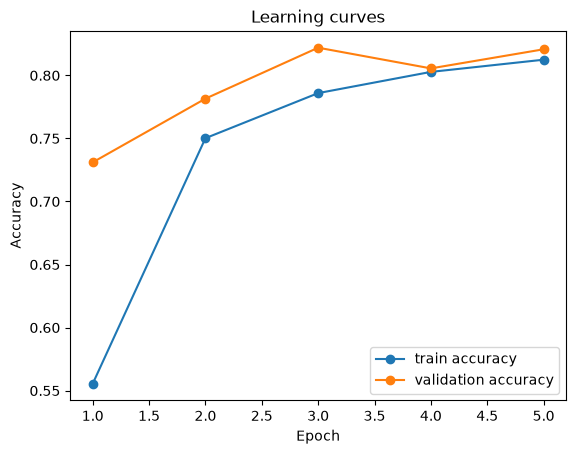

In [4]:
epochs = range(1, len(history)+1)
plt.plot(epochs, [r[1] for r in history], marker="o", label="train accuracy")
plt.plot(epochs, [r[3] for r in history], marker="o", label="validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Learning curves"); plt.legend(); plt.show()
